# Power generation

A worked example of `quicksat`'s power generation: the scenario sample's three orbits, with solar cells on four wing panels that turn to the sun, and on the deck.

**Run all the cells.** The notebook reads `data/scenario.yaml` and the panels of `data/power_system.yaml`, runs the scenario, and works out the power of each panel at each step. Below are the panels in 3D, the power of each panel and of all of them, the energy per orbit, and what the self-shadowing costs.

For how each part works, such as the panels from the model, the solar flux and the self-shadowing, see `docs/power/power_generation_ref.ipynb`.

In [1]:
# Change log. LAST_CHANGE and CHANGE_NOTE are typed in by hand. Update them whenever
# the inputs change, such as a panel added, a new efficiency or a new scenario, so
# that the figures below can be read against what produced them. The run time is
# recorded automatically, and says how stale the outputs stored in this notebook are
# relative to that last change.
from datetime import datetime

LAST_CHANGE = "2026-10-12"
CHANGE_NOTE = (
    "The scenario sample's three orbits, with five panels: the cells on four wing "
    "panels, which turn to the sun and park in imaging, and the cells on the deck. "
    "30% cells, a loss factor of 0.80, and self-shadowing at 512 points a panel. "
    "The file is now power_system.yaml, and slews are a mode of their own."
)

print(f"last change  {LAST_CHANGE}")
print(f"             {CHANGE_NOTE}")
print(f"last run     {datetime.now().astimezone():%Y-%m-%d %H:%M %Z}")

last change  2026-10-12
             The scenario sample's three orbits, with five panels: the cells on four wing panels, which turn to the sun and park in imaging, and the cells on the deck. 30% cells, a loss factor of 0.80, and self-shadowing at 512 points a panel. The file is now power_system.yaml, and slews are a mode of their own.
last run     2026-10-12 22:42 CEST


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt

# Make the in-development quicksat package importable without installing it: walk up
# from the current directory to the repo root (the folder that holds the quicksat
# package) and switch to it. Works whether the notebook runs from sample/, the repo
# root, or the docs build.
here = Path.cwd()
repo_root = next(
    (p for p in (here, *here.parents) if (p / "quicksat" / "__init__.py").exists()),
    None,
)
if repo_root is None:
    raise RuntimeError("could not locate the quicksat repo root")
os.chdir(repo_root)

from quicksat.power.config import PowerSystem
from quicksat.power.generation import run_generation
from quicksat.power.plots import panel_drawing, panel_power_plot, total_power_plot
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.utils.plot_helpers import STYLE

plt.style.use(STYLE)

## The scenario and the panels

The folder `data/` holds the power sample's own copy of the scenario file, `scenario.yaml`, and the 3D model it names, `spacecraft.glb`. The scenario is the scenario sample's: the same orbit, attitudes and activities, with the wings turning to the sun and parking flat in imaging. Only the model differs: it has cells on the deck as well, around the payload housing.

`power_system.yaml` names the panels. Each one is a part of the model, which gives its area and the direction its cells face. A panel on a wing turns with the wing. The table shows each panel's normal where the model draws it, with the wings flat.

A note would appear above the table for any panel typed in by hand, since the self-shadowing cannot cover it. The sample has none.

In [3]:
DATA = Path("sample") / "power" / "data"
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
power_system = PowerSystem.from_yaml_file(DATA / "power_system.yaml")
generation_run = run_generation(power_system, run)

for note in generation_run.notes:
    print(note)
generation_run.panel_table.style.hide(axis="index").format(
    {"area [m2]": "{:.4f}", "fill ratio [%]": "{:.0f}"}
)

panel,part,area [m2],fill ratio [%],normal,turns with
wing +y inner,Wing +y inner cells,0.4026,85,"[+0.000, +0.000, -1.000]",wing +y
wing +y outer,Wing +y outer cells,0.4026,85,"[+0.000, +0.000, -1.000]",wing +y
wing -y inner,Wing -y inner cells,0.4026,85,"[+0.000, +0.000, -1.000]",wing -y
wing -y outer,Wing -y outer cells,0.4026,85,"[+0.000, +0.000, -1.000]",wing -y
deck,Deck cells,0.0716,80,"[+0.000, +0.000, -1.000]",


## The panels in 3D

The model as the file draws it, seen from below, the side the cells face. Each arrow is a panel's normal, and the grey arrows are the body axes. The wings lie flat here, at an angle of 0. Over the run they turn about y. The scenario notebook's viewer shows them turning.

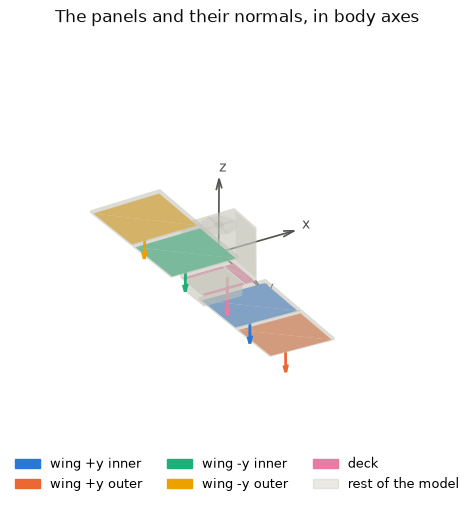

In [4]:
panel_drawing(generation_run, elev=-30)
plt.show()

## The power of each panel

Each panel's power against time, with the eclipses shaded. The four wing panels see the sun alike, so their lines lie close together, and part only where the payload housing shades a panel. In imaging, the wings park flat, and their power drops. The deck cells face the sun fully only in sun pointing.

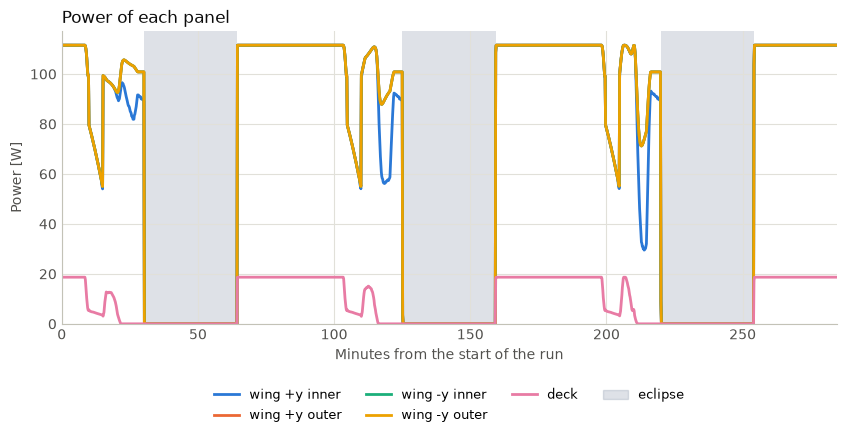

In [5]:
panel_power_plot(generation_run)
plt.show()

## The power of all the panels

The total against time. The dashed line is each orbit's mean power. The orbits are counted from the start of the run, one orbital period each.

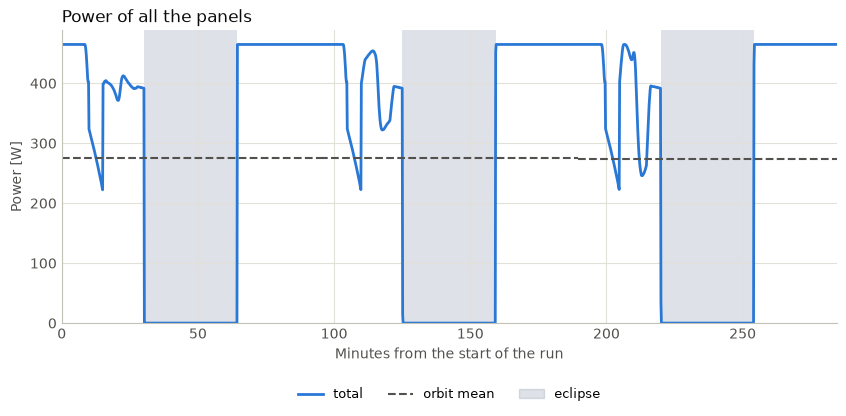

In [6]:
total_power_plot(generation_run)
plt.show()

## The power per orbit

One row for each whole orbit: the time in eclipse, the mean power over the whole orbit and over its sunlit part, and the energy generated. The sunlit mean is the energy generated outside the eclipse, divided by the time outside it. A cut orbit at the end of a run would be left out.

In [7]:
generation_run.orbit_table.style.hide(axis="index").format(
    {
        "eclipse [min]": "{:.2f}",
        "mean power [W]": "{:.1f}",
        "sunlit mean power [W]": "{:.1f}",
        "energy [Wh]": "{:.1f}",
    }
)

orbit,start [UTC],eclipse [min],mean power [W],sunlit mean power [W],energy [Wh]
1,2026-10-01T09:00:00.000,34.32,275.5,430.6,435.5
2,2026-10-01T10:34:51.055,34.32,275.1,429.9,434.8
3,2026-10-01T12:09:42.109,34.32,273.1,426.8,431.8


## The energy of each panel per orbit

The same orbits, with the energy split between the panels.

In [8]:
table = generation_run.panel_energy_table
table.style.hide(axis="index").format(
    {column: "{:.1f}" for column in table.columns if column != "orbit"}
)

orbit,wing +y inner [Wh],wing +y outer [Wh],wing -y inner [Wh],wing -y outer [Wh],deck [Wh],total [Wh]
1,103.9,106.0,106.0,106.0,13.7,435.5
2,102.9,106.0,106.0,106.0,13.8,434.8
3,102.0,105.3,105.3,105.3,13.9,431.8


## Self-shadowing

The rest of the model can shade the panels: here, the payload housing on the deck. The table gives each panel's lowest lit fraction, the time it is more than 1% shaded, and the energy the shading costs over the run. The power above already includes it.

In [9]:
generation_run.shading_table.style.hide(axis="index").format(
    {
        "lowest lit fraction": "{:.3f}",
        "shaded [min]": "{:.1f}",
        "energy lost [Wh]": "{:.2f}",
        "energy lost [%]": "{:.2f}",
    }
)

panel,lowest lit fraction,shaded [min],energy lost [Wh],energy lost [%]
wing +y inner,0.398,31.3,8.49,2.68
wing +y outer,1.000,0.0,0.00,0.00
wing -y inner,1.000,0.0,0.00,0.00
wing -y outer,1.000,0.0,0.00,0.00
deck,0.214,38.2,3.68,8.17


## Changing the panels

Edit `sample/power/data/power_system.yaml`, or the scenario copy next to it, and run the notebook again from the top. The notebook never writes those files.

For example, set `enabled: false` under `self_shadowing`. The deck cells and the shaded wing panel then gain the energy the housing took from them.

Or set `loss_factor` to the value for the end of life. Every panel's power drops in proportion.

Or let the wings track the sun in imaging too: remove `park` from the articulations in `scenario.yaml`. The dips in imaging become small.

Or try a panel without changing the model: uncomment `side +x`. It is typed in, so it stays fixed in body axes and is never shaded, and the notebook notes it.

The battery and the conditioning in the same file are for the power budget, `power_budget.ipynb`.